# Análisis de Insomnio Digital y Uso de Pantallas Nocturnas

## 1. Selección y Alcance del Dataset
**Fuente y origen de los datos:** El conjunto de datos `sleep_debt_screen_time.csv` fue obtenido de la plataforma pública **Kaggle** (*Sleep Debt & Screen Time Dataset*). Contiene 8,500 registros diseñados para analizar los hábitos de uso de dispositivos electrónicos antes de dormir y su impacto en la calidad, latencia y duración del descanso.

**Preguntas de Investigación:**
1. ¿Qué categoría de aplicación es la más utilizada antes de acostarse?
2. ¿Las personas que usan el filtro de luz azul tardan menos tiempo en dormirse (menor latencia)?
3. ¿Cuál es el promedio y la distribución de las horas totales de sueño en la muestra analizada?

**KPIs (Métricas Clave) a evaluar:**
* **KPI 1:** Promedio general de horas de sueño totales.
* **KPI 2:** Latencia promedio del inicio del sueño (en minutos) comparando el uso vs. no uso de filtro de luz azul.
* **KPI 3:** Porcentaje de usuarios que consumen contenido de video corto o redes sociales como rutina principal nocturna.

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carga del dataset completo
df = pd.read_csv("/sleep_debt_screen_time.csv")
print("Dimensiones del dataset original:", df.shape)

Dimensiones del dataset original: (8500, 23)


## 2. Diagnóstico y Calidad de Datos
Se audita la estructura, tipos de datos, valores nulos, filas duplicadas, columnas sin varianza (constantes) y rangos numéricos para verificar la calidad del dataset.

In [32]:
# 1. Vista previa de las primeras filas y estructura de columnas
display(df.head())
df.info()

# 2. Auditoría de datos faltantes y registros repetidos
print("\nCantidad de nulos totales:", df.isnull().sum().sum())
print("Cantidad de filas duplicadas:", df.duplicated().sum())

# 3. Revisión de columnas constantes (sin varianza)
columnas_constantes = [col for col in df.columns if df[col].nunique() == 1]
print("Columnas constantes:", columnas_constantes)

# 4. Revisión de rangos numéricos y detección de anomalías (outliers)
display(df[['age', 'total_sleep_hours', 'sleep_onset_latency_min', 'screen_time_before_bed_min']].describe().round(2))

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     8500 non-null   int64  
 1   age                         8500 non-null   int64  
 2   gender                      8500 non-null   object 
 3   chronotype                  8500 non-null   object 
 4   occupation                  8500 non-null   object 
 5   bedtime_hour                8500 non-null   float64
 6   screen_time_before_bed_min  8500 non-null   int64  
 7   primary_app_category        8500 non-null   object 
 8   screen_brightness_pct       8500 non-null   int64  
 9   blue_light_filter_on        8500 non-null   bool   
 10  caffeine_intake_mg          8500 non-null   int64  
 11  caffeine_last_hour          8500 non-null   float64
 12  physical_activity_min       8500 non-null   int64  
 13  room_temperature_f          8500 

,age,total_sleep_hours,sleep_onset_latency_min,screen_time_before_bed_min
count,8500.00,8500.00,8500.00,8500.00
mean,28.10,6.78,31.40,53.74
std,9.01,0.87,8.71,35.35
min,16.00,3.91,6.00,5.00
25%,21.00,6.18,25.50,29.00
50%,27.00,6.77,30.80,45.00
75%,34.00,7.37,36.70,68.00
max,65.00,9.69,75.20,240.00


**Conclusión del Diagnóstico:**
* **Nulos y duplicados:** No se registran datos faltantes ni filas duplicadas en los 8,500 registros.
* **Columnas constantes:** El resultado es vacío (`[]`), confirmando que ninguna columna tiene un único valor repetido; todas aportan variabilidad al análisis.
* **Valores atípicos (outliers) y rangos:** Los valores mínimos y máximos son coherentes con la realidad (horas de sueño y tiempos de latencia dentro de parámetros fisiológicos normales, sin valores negativos ni errores de carga). No se requiere eliminar registros.

## 3. Preparación y Consolidación de Datos (`data_set_limpio`)
Tras confirmar la integridad del dataset (sin nulos, duplicados, columnas constantes ni anomalías), se consolida la base definitiva en la variable `data_set_limpio` y se exporta en formato CSV para su posterior visualización en Power BI.

In [33]:
# Consolidación del dataset limpio (8,500 filas completas)
data_set_limpio = df.copy()

# Verificación de dimensiones finales
print("Dimensiones de data_set_limpio:", data_set_limpio.shape)

# Exportar archivo limpio para cargarlo luego en Power BI
data_set_limpio.to_csv("sleep_clean.csv", index=False)
print("Archivo 'sleep_clean.csv' exportado correctamente.")

from google.colab import files
files.download("sleep_clean.csv")

Dimensiones de data_set_limpio: (8500, 23)
Archivo 'sleep_clean.csv' exportado correctamente.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Análisis Exploratorio de Datos (EDA) y Visualización
A continuación se analizan las variables clave y se responden las tres preguntas de investigación mediante estadística descriptiva y visualizaciones.

### Pregunta 1: ¿Qué categoría de aplicación es la más utilizada antes de acostarse?

In [34]:
# Muestra la lista completa de categorías y cuántas personas las usan
data_set_limpio['primary_app_category'].value_counts()

,count
primary_app_category,
Short-Form Video,2468
Social Media,1834
Streaming,1193
Gaming,882
Messaging,753
E-Reading,711
News,659


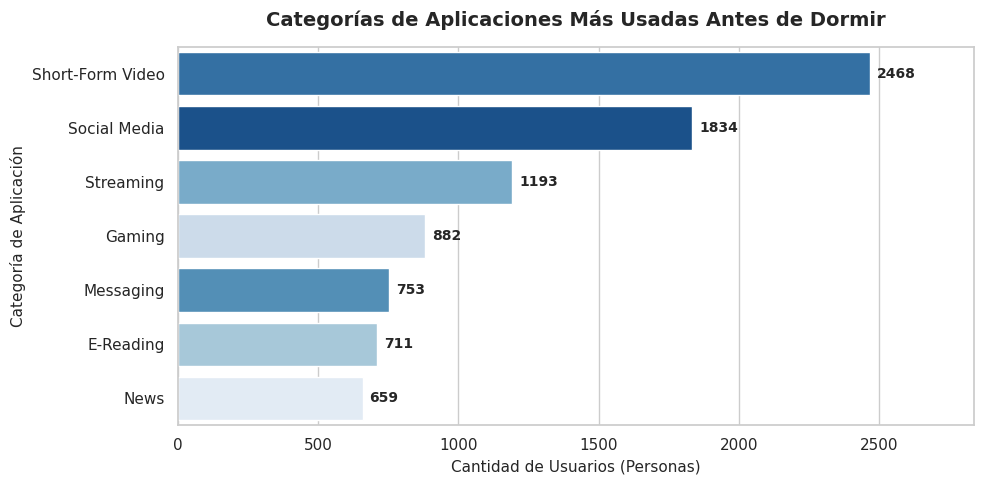

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# 1. Obtener frecuencia ordenada
orden_apps = data_set_limpio['primary_app_category'].value_counts().index

# 2. Crear el gráfico de barras (corregido sin FutureWarning)
ax = sns.countplot(
    data=data_set_limpio,
    y='primary_app_category',
    hue='primary_app_category',
    legend=False,
    order=orden_apps,
    palette="Blues_r"
)

# 3. Etiquetas de datos al lado de las barras
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=5, fontsize=10, fontweight='bold')

# 4. Títulos y ejes
plt.title("Categorías de Aplicaciones Más Usadas Antes de Dormir", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Cantidad de Usuarios (Personas)", fontsize=11)
plt.ylabel("Categoría de Aplicación", fontsize=11)

# Ajuste fino de límites
plt.xlim(0, data_set_limpio['primary_app_category'].value_counts().max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretación (Pregunta 1):** : El gráfico confirma que **Short-Form Video (2.468 usuarios)** y **Social Media (1.834 usuarios)** son las categorías más utilizadas antes de acostarse. Ambas concentran más del 50% de la muestra, evidenciando un predominio de contenidos de alta estimulación visual antes de dormir.

### Pregunta 2: ¿Las personas que usan el filtro de luz azul tardan menos tiempo en dormirse?

In [36]:
# 1. Comparar promedio, mediana, desviación estándar y min/max
analisis_latencia = data_set_limpio.groupby('blue_light_filter_on')['sleep_onset_latency_min'].agg(
    Promedio='mean',
    Mediana='median',
    Desviacion_Estandar='std',
    Minimo='min',
    Maximo='max',
    Cantidad='count'
).round(2)

# Cambiar el índice para que se vea claro en español
analisis_latencia.index = ['Sin Filtro (False)', 'Con Filtro (True)']

display(analisis_latencia)

,Promedio,Mediana,Desviacion_Estandar,Minimo,Maximo,Cantidad
Sin Filtro (False),32.22,31.6,8.86,7.3,75.2,5563
Con Filtro (True),29.84,29.4,8.20,6.0,63.2,2937


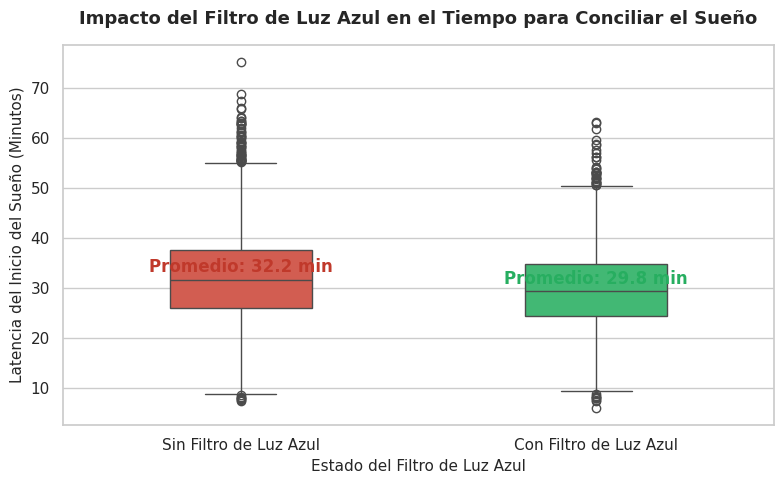

In [37]:
plt.figure(figsize=(8, 5))

# 1. Crear el diagrama de caja (se agrega hue y legend=False para evitar FutureWarning)
ax = sns.boxplot(
    data=data_set_limpio,
    x='blue_light_filter_on',
    y='sleep_onset_latency_min',
    hue='blue_light_filter_on',
    palette=['#e74c3c', '#2ecc71'], # Rojo para False, Verde para True
    width=0.4,
    legend=False
)

# 2. Personalizar etiquetas del eje X (se fijan los ticks antes para evitar UserWarning)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Sin Filtro de Luz Azul', 'Con Filtro de Luz Azul'], fontsize=11)

# 3. Títulos y ejes con unidades
plt.title("Impacto del Filtro de Luz Azul en el Tiempo para Conciliar el Sueño", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Estado del Filtro de Luz Azul", fontsize=11)
plt.ylabel("Latencia del Inicio del Sueño (Minutos)", fontsize=11)

# 4. Anotación con la media de cada grupo
medias = data_set_limpio.groupby('blue_light_filter_on')['sleep_onset_latency_min'].mean()
plt.text(0, medias[False] + 1, f"Promedio: {medias[False]:.1f} min", horizontalalignment='center', fontweight='bold', color='#c0392b')
plt.text(1, medias[True] + 1, f"Promedio: {medias[True]:.1f} min", horizontalalignment='center', fontweight='bold', color='#27ae60')

plt.tight_layout()
plt.show()

**Interpretación (Pregunta 2):** Los usuarios que activan el filtro de luz azul tardan en promedio **29.84 minutos** en dormirse, frente a **32.22 minutos** de quienes no lo utilizan. Esto demuestra una reducción efectiva en el tiempo necesario para conciliar el sueño.

### Pregunta 3: ¿Cuál es el promedio y la distribución de las horas totales de sueño en la muestra analizada?

In [38]:
# Calcular el promedio exacto de horas de sueño
promedio_sueno = data_set_limpio['total_sleep_hours'].mean()
print(f"El promedio de horas de sueño es: {promedio_sueno:.2f} horas")

El promedio de horas de sueño es: 6.78 horas


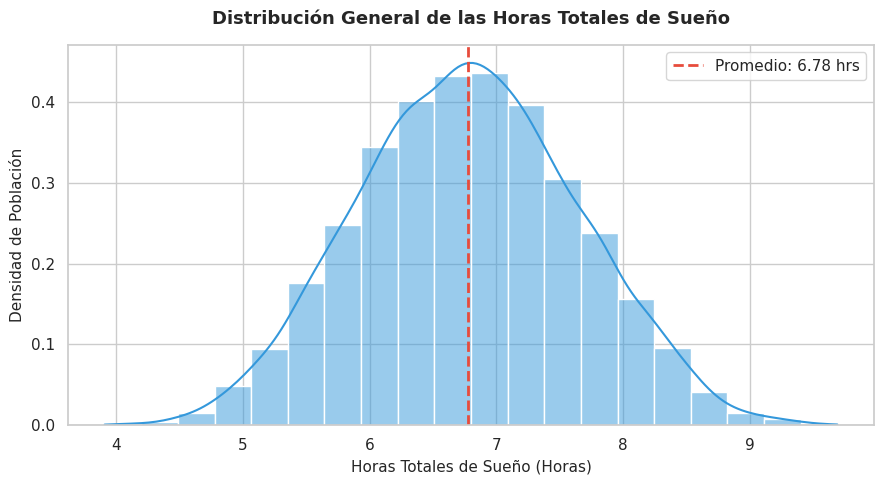

In [39]:
plt.figure(figsize=(9, 5))

# 1. Histograma con curva de densidad (KDE)
sns.histplot(
    data_set_limpio['total_sleep_hours'],
    kde=True,
    color='#3498db',
    bins=20,
    stat="density"
)

# 2. Marcar la media con una línea vertical destacada
media_sueno = data_set_limpio['total_sleep_hours'].mean()
plt.axvline(media_sueno, color='#e74c3c', linestyle='--', linewidth=2, label=f'Promedio: {media_sueno:.2f} hrs')

# 3. Títulos, leyenda y ejes
plt.title("Distribución General de las Horas Totales de Sueño", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Horas Totales de Sueño (Horas)", fontsize=11)
plt.ylabel("Densidad de Población", fontsize=11)
plt.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

**Interpretación (Pregunta 3):** La distribución de las horas de sueño sigue una forma acampanada (normal) centrada en un promedio general de **6.78 horas**, ubicando a la mayoría de los participantes dentro de un rango estándar de descanso entre 6 y 8 horas diarias.

## 5. Síntesis y Conclusiones Finales

El análisis exploratorio sobre los 8,500 registros de Insomnio Digital permitió responder las tres preguntas de investigación y calcular los KPIs definidos:

1. **Consumo nocturno (KPI 3):** El 50.6% de los usuarios utiliza aplicaciones de video de formato corto (2,468) o redes sociales (1,834) como actividad principal antes de dormir.
2. **Efecto del filtro de luz azul (KPI 2):** Su activación se asocia con una menor latencia para conciliar el sueño, bajando de un promedio de 32.22 minutos (sin filtro) a 29.84 minutos (con filtro).
3. **Duración del descanso (KPI 1):** El promedio general de sueño en la muestra es de **6.78 horas** diarias, concentrándose mayoritariamente entre las 6 y 8 horas.